In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

In [ ]:
SUBJECT_IDS = range(1, 110)
RUNS = (3, 4, 7, 8, 11, 12)
DATA_DIR = Path.home() / 'physionet.org/files/eegmmidb/1.0.0'
OUTPUT_DIR = Path.cwd() / 'benchmark_data_ica_64ch'
ICA_FILE = 'ica_blinks.fif'
SFREQ = 160
FMIN, FMAX = 8, 30
TMIN, TMAX = 0.5, 3.5
SEED = 42
EVENT_ID = {'T1': 1, 'T2': 2}

print('Dane:', DATA_DIR)
print('Wynik:', OUTPUT_DIR)

print('Katalog ICA:', ICA_ROOT)
print('Liczba kanałów na wyjściu:', 64)
print('Liczba osób:', len(SUBJECT_IDS), '| Zapisywanie do:', OUTPUT_DIR)

TRYB TESTOWY: False
ICA: True | Katalog ICA: /home/eliza/physionet.org/files/eegmmidb/1.0.0
Puste exclude: warn_keep | Ręczne wyjątki: {}
Liczba kanałów na wyjściu: 64
Liczba osób: 109 | Zapisywanie do: /home/eliza/mgr-phd/benchmark_data_ica_64ch


## 2. Znajdowanie plików EDF

In [ ]:
def paths_for_subject(subject_id):
    subject = f'S{subject_id:03d}'
    paths = [DATA_DIR / subject / f'{subject}R{run:02d}.edf' for run in RUNS]
    if all(path.is_file() for path in paths):
        return paths
    if POBIERZ_BRAKUJACE:
        paths = mne.datasets.eegbci.load_data(
            subject_id, list(RUNS), path=str(DOWNLOAD_CACHE), update_path=False,
        )
        return [Path(p) for p in paths]
    missing = [str(path) for path in paths if not path.is_file()]
    raise FileNotFoundError('Nie znaleziono EDF: ' + '; '.join(missing))


def ica_path_for_subject(subject_id):
    return ICA_ROOT / f'S{subject_id:03d}' / ICA_FILE_NAME


example_paths = paths_for_subject(SUBJECT_IDS[0])
for path in example_paths:
    print('EDF:', path)

for subject_id in SUBJECT_IDS:
    path = ica_path_for_subject(subject_id)
    if not path.is_file():
        raise FileNotFoundError(
            f'Brak indywidualnego ICA dla S{subject_id:03d}: {path}. '
            'Pliki ica_blinks.fif nie pochodzą z oficjalnej bazy PhysioNet. '
            'Przenieś własne pliki z pracy magisterskiej lub ustaw ICA_ROOT.'
        )
print('Znaleziono komplet plików ICA dla wybranych uczestników.')

example_raw = mne.io.read_raw_edf(example_paths[0], preload=False, verbose='ERROR')
mne.datasets.eegbci.standardize(example_raw)
ALL_64_CHANNELS = tuple(example_raw.ch_names)
if len(ALL_64_CHANNELS) != 64:
    raise ValueError(f'Oczekiwano 64 kanałów PhysioNet, otrzymano {len(ALL_64_CHANNELS)}.')
CHANNELS = ALL_64_CHANNELS if USE_ALL_64_CHANNELS else CHANNELS_19
if not set(CHANNELS).issubset(set(ALL_64_CHANNELS)):
    raise ValueError('Brak kanałów wymaganych w konfiguracji.')
print('Kanały na wyjściu:', len(CHANNELS))
print('Kolejność:', CHANNELS)
del example_raw

EDF: /home/eliza/physionet.org/files/eegmmidb/1.0.0/S001/S001R03.edf
EDF: /home/eliza/physionet.org/files/eegmmidb/1.0.0/S001/S001R04.edf
EDF: /home/eliza/physionet.org/files/eegmmidb/1.0.0/S001/S001R07.edf
EDF: /home/eliza/physionet.org/files/eegmmidb/1.0.0/S001/S001R08.edf
EDF: /home/eliza/physionet.org/files/eegmmidb/1.0.0/S001/S001R11.edf
EDF: /home/eliza/physionet.org/files/eegmmidb/1.0.0/S001/S001R12.edf
Znaleziono komplet plików ICA dla wybranych uczestników.
Kanały na wyjściu: 64
Kolejność: ('FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'T9', 'T10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz')


### Diagnostyka zgodności kanałów ICA i EDF (opcjonalna)

In [ ]:
first_subject = f'S{SUBJECT_IDS[0]:03d}'
ica_preview = mne.preprocessing.read_ica(ica_path_for_subject(SUBJECT_IDS[0]), verbose='ERROR')
edf_preview = mne.io.read_raw_edf(example_paths[0], preload=False, verbose='ERROR')
mne.datasets.eegbci.standardize(edf_preview)
print('ICA:', ica_preview.ch_names)
print('EDF:', edf_preview.ch_names)
print('Tylko w ICA:', sorted(set(ica_preview.ch_names) - set(edf_preview.ch_names)))
print('Tylko w EDF:', sorted(set(edf_preview.ch_names) - set(ica_preview.ch_names)))

ICA: ['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'TP9', 'TP10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']
EDF: ['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'T9', 'T10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']
Tylko w ICA (nazwy dosłowne): ['TP10', 'TP9']
Tylko w EDF (nazwy dosłowne): ['T10', 'T9']
Uwaga: różnice zapisu nie muszą oznaczać różnych elektrod.


## 3. ICA z pracy magisterskiej i tworzenie epok

In [ ]:
ICA_CACHE = {}
ICA_REPORT = {}
SFREQ_REPORT = {}
ICA_ALIAS_REPORTED = set()
assert ICA_EMPTY_EXCLUDE_POLICY in {'warn_keep', 'error'}, (
    "ICA_EMPTY_EXCLUDE_POLICY musi być 'warn_keep' lub 'error'")

def prepare_raw_before_ica(path):
    path = Path(path)
    raw = mne.io.read_raw_edf(path, preload=True, verbose='ERROR')
    mne.datasets.eegbci.standardize(raw)
    if set(raw.ch_names) != set(ALL_64_CHANNELS):
        raise ValueError(f'{path}: niezgodny zestaw 64 kanałów EDF.')
    raw.reorder_channels(list(ALL_64_CHANNELS))
    raw.set_montage('standard_1005', on_missing='raise', verbose='ERROR')

    initial_sfreq = float(raw.info['sfreq'])
    SFREQ_REPORT[str(path)] = {'file': path.name, 'subject': path.parent.name,
                               'sfreq_original_hz': initial_sfreq,
                               'sfreq_final_hz': float(SFREQ)}
    if not np.isclose(initial_sfreq, SFREQ):
        raw.resample(SFREQ, verbose='ERROR')
        print(f'RESAMPLING {path.name}: {initial_sfreq:g} → {SFREQ:g} Hz')

    raw.filter(FMIN, FMAX, method='fir', fir_design='firwin', verbose='ERROR')
    raw.set_eeg_reference('average', projection=False, verbose='ERROR')
    return raw


def ica_channel_key(name):
    """Porównuje nazwy elektrod niezależnie od wielkości liter i kropek.
    T9 -> TP9 i T10 -> TP10
    """
    key = str(name).strip().rstrip('.').upper()
    return ICA_CHANNEL_ALIASES.get(key, key)


def build_unique_channel_map(names, source):
    result = {}
    for name in names:
        key = ica_channel_key(name)
        if key in result:
            raise ValueError(
                f'{source}: nazwy {result[key]!r} i {name!r} wskazują '
                f'na ten sam klucz {key!r}; wymagane jest ręczne sprawdzenie.'
            )
        result[key] = name
    return result


def validate_ica_channels(ica, reference_names, subject):
    """Sprawdza zgodność elektrod, a w razie błędu wypisuje konkretne nazwy."""
    edf_map = build_unique_channel_map(reference_names, f'{subject} EDF')
    ica_map = build_unique_channel_map(ica.ch_names, f'{subject} ICA')
    missing_in_ica = sorted(set(edf_map) - set(ica_map))
    missing_in_edf = sorted(set(ica_map) - set(edf_map))
    if missing_in_ica or missing_in_edf:
        raise ValueError(
            f'{subject}: niezgodne elektrody (ICA={len(ica.ch_names)}, '
            f'EDF={len(reference_names)}).\n'
            f'Obecne w EDF, brak w ICA: {missing_in_ica}\n'
            f'Obecne w ICA, brak w EDF: {missing_in_edf}\n'
            f'Pierwsze nazwy ICA: {ica.ch_names[:12]}\n'
            f'Pierwsze nazwy EDF: {list(reference_names)[:12]}\n'
            'Nie należy dopasowywać kanałów tylko według liczby lub indeksu.'
        )
    renamed = [(edf_map[k], ica_map[k]) for k in ica_map
               if edf_map[k] != ica_map[k]]
    if renamed and subject not in ICA_ALIAS_REPORTED:
        print(f'{subject}: zaakceptowane aliasy ICA/EDF: {renamed}')
        ICA_ALIAS_REPORTED.add(subject)
    return edf_map, ica_map


def get_saved_ica(subject):
    if subject not in ICA_CACHE:
        file = ICA_ROOT / subject / ICA_FILE_NAME
        if not file.is_file():
            raise FileNotFoundError(f'Brak pliku ICA: {file}')
        ica = mne.preprocessing.read_ica(file, verbose='ERROR')
        if len(ica.ch_names) != 64:
            raise ValueError(
                f'{subject}: ICA ma {len(ica.ch_names)} kanałów; '
                'ten eksperyment wymaga ICA wyuczonego na 64 elektrodach.'
            )
        validate_ica_channels(ica, ALL_64_CHANNELS, subject)
        if not np.isclose(float(ica.info['sfreq']), SFREQ):
            raise ValueError(
                f'{subject}: ICA zapisano dla {ica.info["sfreq"]} Hz, '
                f'a docelowe nagranie ma {SFREQ} Hz. Sprawdź zgodność preprocessing.'
            )
        source = 'override' if subject in ICA_EXCLUDE_OVERRIDES else 'fif'
        selected = (ICA_EXCLUDE_OVERRIDES[subject]
                    if source == 'override' else ica.exclude)
        excluded = sorted({int(k) for k in selected})
        bad = [k for k in excluded if k < 0 or k >= int(ica.n_components_)]
        if bad:
            raise ValueError(
                f'{subject}: indeksy poza zakresem komponentów ICA: {bad}; '
                f'dozwolone 0..{int(ica.n_components_) - 1}')
        if not excluded and ICA_EMPTY_EXCLUDE_POLICY == 'error':
            raise ValueError(
                f'{subject}: ICA.exclude jest puste. Obejrzyj komponenty ICA '
                'albo wybierz ICA_EMPTY_EXCLUDE_POLICY="warn_keep".')
        status = ('applied' if excluded else 'not_applied_empty_exclude')
        if not excluded:
            print(f'UWAGA {subject}: exclude=[] — NIE zastosowano ICA dla tej osoby. '
                  'Sygnał pozostaje po filtracji i referencji; odnotowano to w raporcie.')
        ica.exclude = excluded
        edf_map, ica_map = validate_ica_channels(ica, ALL_64_CHANNELS, subject)
        aliases_used = [
            {'edf': edf_map[k], 'ica': ica_map[k]}
            for k in ica_map if edf_map[k] != ica_map[k]
        ]
        ICA_CACHE[subject] = ica
        ICA_REPORT[subject] = {
            'subject': subject, 'ica_file': str(file),
            'n_ica_components': int(ica.n_components_),
            'excluded_components': excluded,
            'n_excluded': len(excluded),
            'ica_application_status': status,
            'exclude_source': source,
            'channel_aliases': aliases_used,
            'ica_fit_sfreq_hz': float(ica.info['sfreq']),
        }
        print(f'{subject}: ICA wczytane, usuwane komponenty: {excluded}')
    return ICA_CACHE[subject]


def clean_raw_with_ica(raw, subject):
    if not USE_ICA:
        return raw
    ica = get_saved_ica(subject)
    if not ica.exclude:
        return raw.copy()
    edf_map, ica_map = validate_ica_channels(ica, raw.ch_names, subject)
    to_ica_names = {edf_map[key]: ica_name
                    for key, ica_name in ica_map.items()
                    if edf_map[key] != ica_name}
    to_standard_names = {ica_name: edf_map[key]
                         for key, ica_name in ica_map.items()
                         if edf_map[key] != ica_name}

    cleaned = raw.copy()
    if to_ica_names:
        cleaned.rename_channels(to_ica_names)
    cleaned.reorder_channels(list(ica.ch_names))
    cleaned = ica.apply(cleaned, verbose='ERROR')

    if to_standard_names:
        cleaned.rename_channels(to_standard_names)
    cleaned.reorder_channels(list(ALL_64_CHANNELS))
    return cleaned


def process_one_run(path):
    path = Path(path)
    subject = path.parent.name
    raw = prepare_raw_before_ica(path)
    raw = clean_raw_with_ica(raw, subject)
    missing = sorted(set(CHANNELS) - set(raw.ch_names))
    if missing:
        raise ValueError(f'{path}: brak kanałów po ICA: {missing}')
    raw.pick(list(CHANNELS))
    raw.reorder_channels(list(CHANNELS))

    events, _ = mne.events_from_annotations(raw, event_id=EVENT_ID, verbose='ERROR')
    if not len(events):
        raise ValueError(f'{path}: brak zdarzeń T1/T2')
    epochs = mne.Epochs(
        raw, events, event_id=EVENT_ID, tmin=TMIN, tmax=TMAX,
        baseline=None, reject_by_annotation=True, preload=True, verbose='ERROR'
    )
    X_run = (epochs.get_data() * 1e6).astype('float32')  # V → µV
    y_run = (epochs.events[:, 2] == EVENT_ID['T1']).astype('uint8')
    sample_events = epochs.events[:, 0].astype('int64')
    return X_run, y_run, sample_events


X_probe, y_probe, samples_probe = process_one_run(example_paths[0])
print('Pierwsze nagranie, X:', X_probe.shape)
print('Etykiety:', dict(zip(*np.unique(y_probe, return_counts=True))))
print('Amplituda [µV]:', float(X_probe.min()), float(X_probe.max()))
assert X_probe.shape[1:] == (len(CHANNELS), int(round((TMAX-TMIN)*SFREQ))+1)


S001: zaakceptowane aliasy ICA/EDF: [('T9', 'TP9'), ('T10', 'TP10')]
S001: ICA wczytane, usuwane komponenty: [0, 2, 5, 6]
Pierwsze nagranie, X: (30, 64, 481)
Etykiety: {0: 22, 1: 8}
Amplituda [µV]: -203.0146484375 122.29359436035156


## 3a. Kontrola ICA — przed i po oczyszczaniu

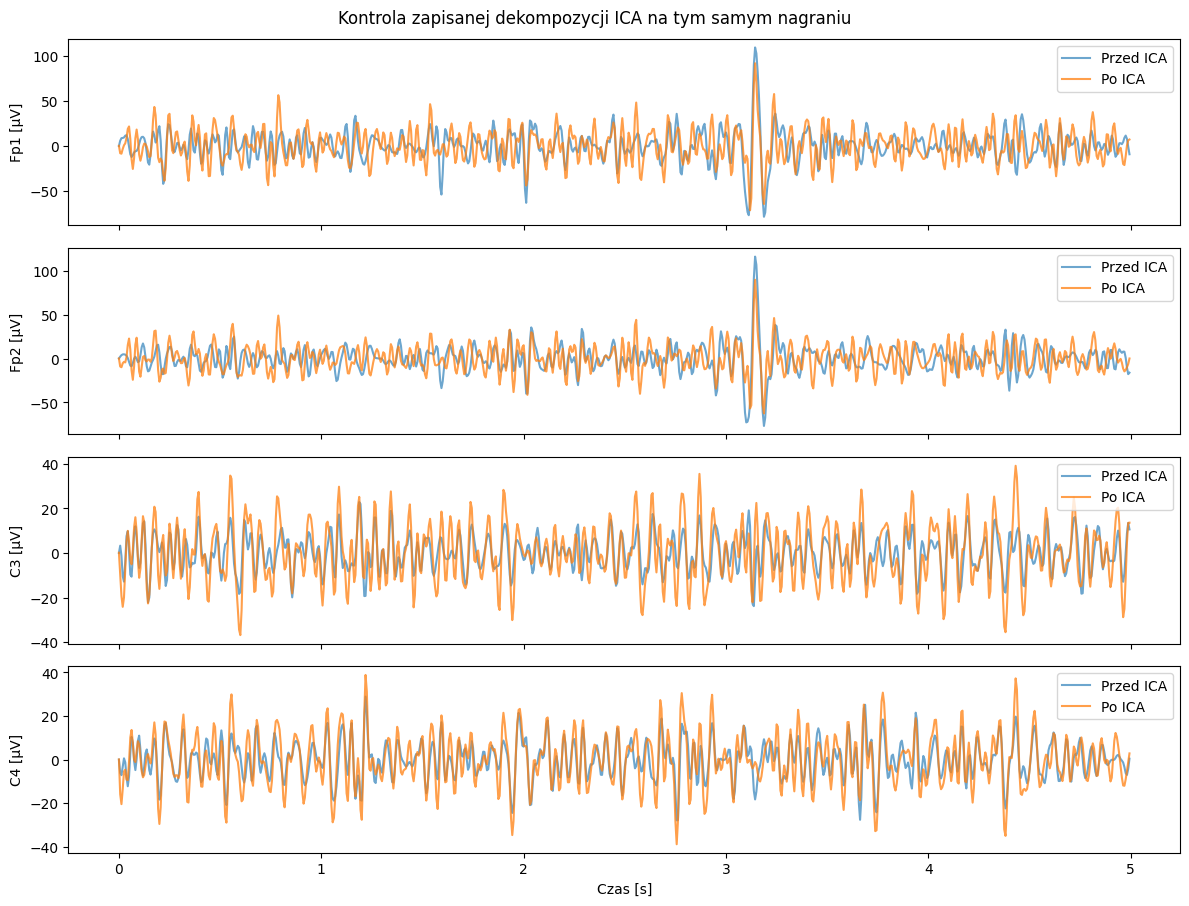

Komponenty wykluczone: [0, 2, 5, 6]


In [ ]:
if USE_ICA:
    raw_before = prepare_raw_before_ica(example_paths[0])
    raw_after = clean_raw_with_ica(raw_before, example_paths[0].parent.name)
    channels_preview = [ch for ch in ('Fp1', 'Fp2', 'C3', 'C4') if ch in raw_before.ch_names]
    duration_s = min(5, raw_before.times[-1])
    t = np.arange(int(duration_s * SFREQ)) / SFREQ
    fig, axs = plt.subplots(len(channels_preview), 1, figsize=(12, 2.3*len(channels_preview)), sharex=True)
    axs = np.atleast_1d(axs)
    for ax, ch in zip(axs, channels_preview):
        a = raw_before.get_data(picks=[ch], start=0, stop=len(t))[0] * 1e6
        b = raw_after.get_data(picks=[ch], start=0, stop=len(t))[0] * 1e6
        ax.plot(t, a, label='Przed ICA', alpha=0.65)
        ax.plot(t, b, label='Po ICA', alpha=0.75)
        ax.set(ylabel=f'{ch} [µV]')
        ax.legend(loc='upper right')
    axs[-1].set_xlabel('Czas [s]')
    fig.suptitle('Kontrola zapisanej dekompozycji ICA na tym samym nagraniu')
    plt.tight_layout()
    plt.show()
    print('Komponenty wykluczone:', ICA_REPORT[example_paths[0].parent.name]['excluded_components'])
    del raw_before, raw_after
else:
    print('ICA wyłączone w konfiguracji.')


### 3b. Kontrola S083 — dlaczego `exclude` jest puste?

In [ ]:
subject_to_check = 'S083'
if USE_ICA:
    file = ICA_ROOT / subject_to_check / ICA_FILE_NAME
    check = mne.preprocessing.read_ica(file, verbose='ERROR')
    print('Uczestnik:', subject_to_check)
    print('Liczba komponentów ICA:', check.n_components_)
    print('Komponenty zapisane w exclude:', check.exclude)
    print('Liczba kanałów ICA:', len(check.ch_names))


Uczestnik: S083
Liczba komponentów ICA: 53
Komponenty zapisane w exclude: []
Liczba kanałów ICA: 64


## 4. Wizualizacja epoki i widma

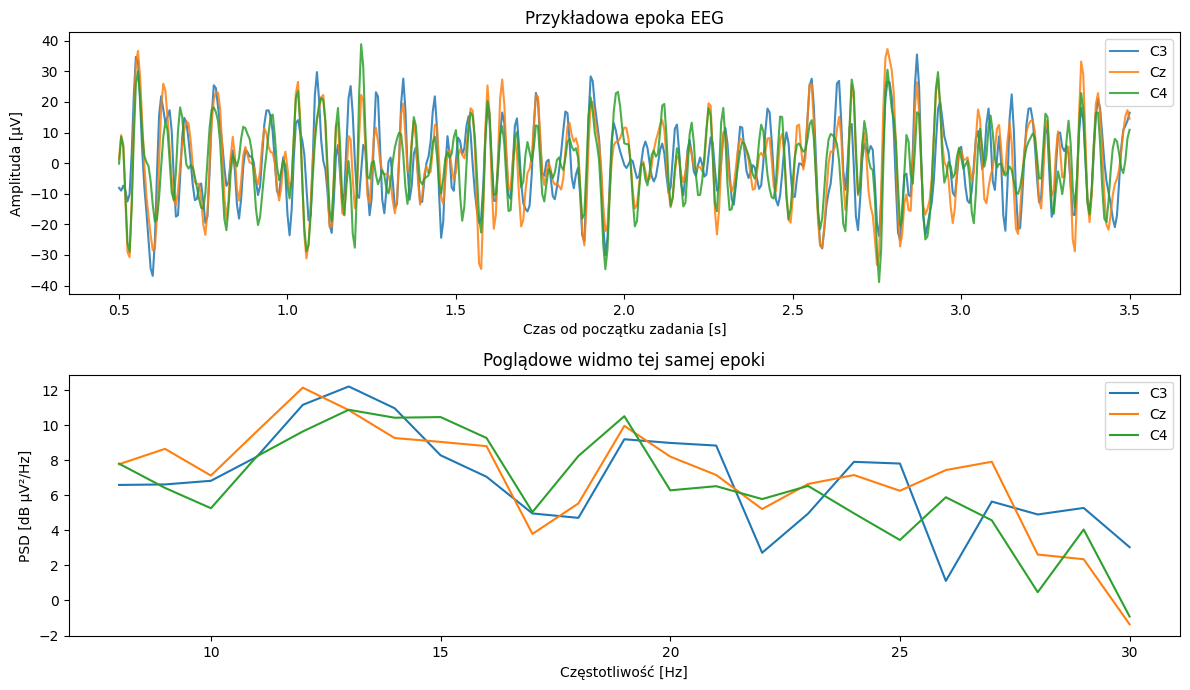

In [9]:
example = X_probe[0]
t = np.arange(example.shape[1]) / SFREQ + TMIN
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for channel in ('C3', 'Cz', 'C4'):
    ci = CHANNELS.index(channel)
    axes[0].plot(t, example[ci], label=channel, alpha=0.85)
axes[0].set(xlabel='Czas od początku zadania [s]', ylabel='Amplituda [µV]', title='Przykładowa epoka EEG')
axes[0].legend()

from scipy.signal import welch
for channel in ('C3', 'Cz', 'C4'):
    freq, psd = welch(example[CHANNELS.index(channel)], fs=SFREQ, nperseg=160, noverlap=80)
    select = (freq >= 8) & (freq <= 30)
    axes[1].plot(freq[select], 10 * np.log10(np.maximum(psd[select], 1e-12)), label=channel)
axes[1].set(xlabel='Częstotliwość [Hz]', ylabel='PSD [dB µV²/Hz]', title='Poglądowe widmo tej samej epoki')
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Wczytanie wszystkich wybranych osób i nagrań

In [10]:
X_parts, y_parts, subject_parts, trial_ids_list = [], [], [], []
subject_rows = []
for subject_id in SUBJECT_IDS:
    subject = f'S{subject_id:03d}'
    total = 0
    for run, path in zip(RUNS, paths_for_subject(subject_id)):
        X_run, y_run, event_samples = process_one_run(path)
        if len(y_run) == 0:
            raise ValueError(f'Nie znaleziono użytecznych epok w {path}')
        X_parts.append(X_run)
        y_parts.append(y_run)
        subject_parts.append(np.repeat(subject, len(y_run)))
        trial_ids_list.extend(
            f'{subject}_R{run:02d}_at_{sample}' for sample in event_samples
        )
        total += len(y_run)
    subject_rows.append({'subject': subject, 'n_epochs': total})
    print(f'{subject}: {total} epok')

X = np.concatenate(X_parts).astype(np.float32, copy=False)
y = np.concatenate(y_parts).astype(np.uint8, copy=False)
subjects = np.concatenate(subject_parts)
trial_ids = np.asarray(trial_ids_list, dtype='U40')
assert len(X) == len(y) == len(subjects) == len(trial_ids)
assert len(np.unique(trial_ids)) == len(trial_ids), 'Powtórzone identyfikatory epok!'
assert X.shape[1:] == (len(CHANNELS), int(round((TMAX-TMIN)*SFREQ))+1)
assert np.isfinite(X).all(), 'Dane zawierają NaN lub Inf'
print('\nWspólny tensor EEG:', X.shape, '(epoki, kanały, próbki)')
print('Klasy: 0=prawa pięść, 1=lewa pięść')

S001: 180 epok
S002: zaakceptowane aliasy ICA/EDF: [('T9', 'TP9'), ('T10', 'TP10')]
S002: ICA wczytane, usuwane komponenty: [0, 1, 10, 16]
S002: 180 epok
S003: zaakceptowane aliasy ICA/EDF: [('T9', 'TP9'), ('T10', 'TP10')]
S003: ICA wczytane, usuwane komponenty: [0, 1, 2, 5, 17]
S003: 180 epok
S004: zaakceptowane aliasy ICA/EDF: [('T9', 'TP9'), ('T10', 'TP10')]
S004: ICA wczytane, usuwane komponenty: [1, 2]
S004: 180 epok
S005: zaakceptowane aliasy ICA/EDF: [('T9', 'TP9'), ('T10', 'TP10')]
S005: ICA wczytane, usuwane komponenty: [0, 5]
S005: 180 epok
S006: zaakceptowane aliasy ICA/EDF: [('T9', 'TP9'), ('T10', 'TP10')]
S006: ICA wczytane, usuwane komponenty: [0]
S006: 180 epok
S007: zaakceptowane aliasy ICA/EDF: [('T9', 'TP9'), ('T10', 'TP10')]
S007: ICA wczytane, usuwane komponenty: [0, 10, 12, 20]
S007: 180 epok
S008: zaakceptowane aliasy ICA/EDF: [('T9', 'TP9'), ('T10', 'TP10')]
S008: ICA wczytane, usuwane komponenty: [0, 1, 2, 3, 35]
S008: 180 epok
S009: zaakceptowane aliasy ICA/EDF

## 6. Kontrola jakości: liczebność klas i uczestników

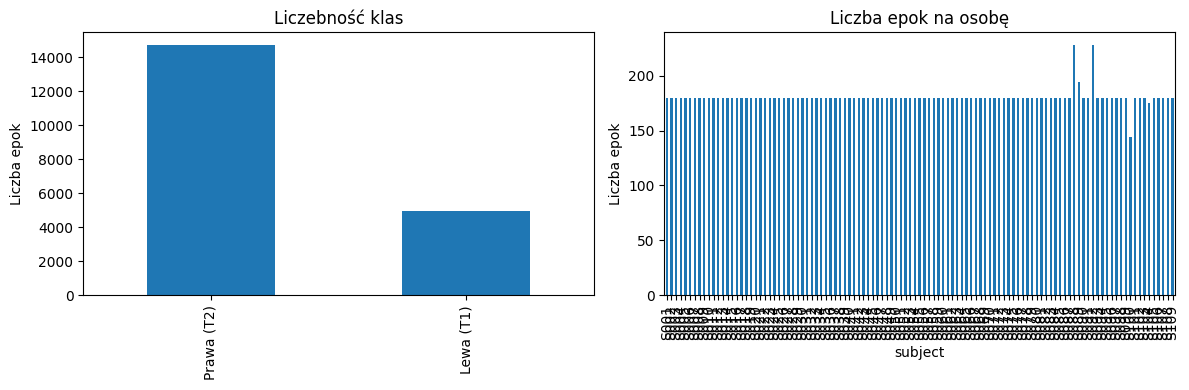

Wartości: {'Prawa (T2)': 14739, 'Lewa (T1)': 4950}


In [11]:
class_counts = pd.Series(y).map({0:'Prawa (T2)', 1:'Lewa (T1)'}).value_counts()
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
class_counts.plot(kind='bar', ax=axs[0], title='Liczebność klas')
pd.DataFrame(subject_rows).plot(x='subject', y='n_epochs', kind='bar', legend=False, ax=axs[1], title='Liczba epok na osobę')
axs[0].set_ylabel('Liczba epok')
axs[1].set_ylabel('Liczba epok')
plt.tight_layout()
plt.show()
print('Wartości:', class_counts.to_dict())

## 7. Podział na 5 foldów — rozłączne osoby

- Zewnętrzny `GroupKFold`: 20% osób na test w każdym foldzie.
- Wewnętrzny `GroupShuffleSplit`: walidacja z części treningowej, również po osobach.
- Ten sam `splits.npz` będzie używany w EEGNet, CNN+PSD, CSP, FBCSP i Riemann.
- **Żaden element testu nie może wpływać na uczenie normalizatora, wybór cech ani próg decyzji.**

In [12]:
if len(np.unique(subjects)) < 5:
    raise ValueError('Potrzeba co najmniej 5 osób do GroupKFold(5).')
outer = GroupKFold(n_splits=5)
split_arrays = {}
split_summaries = []
for fold, (trainval_idx, test_idx) in enumerate(outer.split(X, y, groups=subjects), start=1):
    inner = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED + fold)
    rel_train, rel_val = next(inner.split(X[trainval_idx], y[trainval_idx], groups=subjects[trainval_idx]))
    train_idx, val_idx = trainval_idx[rel_train], trainval_idx[rel_val]
    parts = {'train': train_idx, 'val': val_idx, 'test': test_idx}
    person_sets = {name: set(subjects[ix]) for name, ix in parts.items()}
    assert not (person_sets['train'] & person_sets['val'])
    assert not (person_sets['train'] & person_sets['test'])
    assert not (person_sets['val'] & person_sets['test'])
    assert all(len(np.unique(y[ix])) == 2 for ix in parts.values()), 'W zbiorze brakuje klasy'
    for name, ix in parts.items():
        split_arrays[f'{name}_{fold}'] = ix.astype(np.int32)
    split_summaries.append({
        'fold': fold,
        'train_epochs': len(train_idx), 'val_epochs': len(val_idx), 'test_epochs': len(test_idx),
        'train_subjects': sorted(person_sets['train']),
        'val_subjects': sorted(person_sets['val']),
        'test_subjects': sorted(person_sets['test']),
    })

summary_df = pd.DataFrame(split_summaries)[['fold','train_epochs','val_epochs','test_epochs']]
display(summary_df)
print('Sprawdzono rozłączność uczestników dla każdego foldu.')

,fold,train_epochs,val_epochs,test_epochs
0,1,12482,3235,3972
1,2,12573,3288,3828
2,3,12480,3240,3969
3,4,12494,3235,3960
4,5,12489,3240,3960


Sprawdzono rozłączność uczestników dla każdego foldu.


## 8. Zapis wspólnego zestawu danych i podziałów

**Nie generuj ponownie foldów dla innych modeli.** Następne notebooki mają czytać zapisane tutaj pliki.

In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
np.savez_compressed(OUTPUT_DIR / 'epochs.npz',
    X=X, y=y, subjects=subjects, trial_ids=trial_ids,
    channel_names=np.asarray(CHANNELS)
)
np.savez_compressed(OUTPUT_DIR / 'splits.npz', **split_arrays)
manifest = {
    'dataset':'PhysioNet EEGMMIDB v1.0.0',
    'task':'motor imagery left vs right',
    'label_meaning': {'0':'T2 - prawa pięść', '1':'T1 - lewa pięść'},
    'runs':list(RUNS), 'sampling_rate_hz':SFREQ,
    'bandpass_hz':[FMIN,FMAX], 'epoch_seconds':[TMIN,TMAX],
    'baseline':None, 'ica':bool(USE_ICA),
    'ica_file_name': ICA_FILE_NAME if USE_ICA else None,
    'ica_per_subject': list(ICA_REPORT.values()) if USE_ICA else [],
    'ica_training_data_provenance_verified': False,
    'ica_empty_exclude_policy': ICA_EMPTY_EXCLUDE_POLICY if USE_ICA else None,
    'ica_empty_exclude_subjects': [
        k for k, v in ICA_REPORT.items()
        if v['ica_application_status'] == 'not_applied_empty_exclude'
    ],
    'ica_channel_aliases': ICA_CHANNEL_ALIASES if USE_ICA else {},
    'original_sampling_frequencies': list(SFREQ_REPORT.values()),
    'reference':'average on full 64 channels, before ICA/channel selection',
    'channels':list(CHANNELS), 'units':'microvolts',
    'channel_mode': '64' if USE_ALL_64_CHANNELS else '19',
    'n_trials':int(len(y)), 'n_subjects':int(len(np.unique(subjects))),
    'subject_ids': list(map(int, SUBJECT_IDS)),
    'class_counts': {str(i):int(np.sum(y==i)) for i in (0,1)},
    'seed_inner_validation':SEED,
    'folds':split_summaries,
    'notes':'Nie zmieniać X, y ani indeksów foldów między modelami. Przetwarzanie specyficzne dla modelu po train/val/test.'
}
pd.DataFrame(SFREQ_REPORT.values()).to_csv(OUTPUT_DIR / 'sampling_frequencies.csv', index=False)
skipped = [k for k, v in ICA_REPORT.items()
            if v['ica_application_status'] == 'not_applied_empty_exclude']
print('Uczestnicy bez korekcji ICA z powodu pustego exclude:', skipped)
pd.DataFrame(ICA_REPORT.values()).to_json(OUTPUT_DIR / 'ica_report.json', orient='records', indent=2, force_ascii=False)
(OUTPUT_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name, '—', round(file.stat().st_size / (1024**2), 2), 'MB')

Uczestnicy bez korekcji ICA z powodu pustego exclude: ['S083']
epochs.npz — 2147.82 MB
ica_report.json — 0.05 MB
manifest.json — 0.15 MB
sampling_frequencies.csv — 0.02 MB
splits.npz — 0.13 MB


## 9. Kontrola plików po ponownym wczytaniu

In [14]:
with np.load(OUTPUT_DIR / 'epochs.npz', allow_pickle=False) as saved:
    assert saved['X'].shape == X.shape
    assert np.array_equal(saved['y'], y)
    assert np.array_equal(saved['trial_ids'], trial_ids)
with np.load(OUTPUT_DIR / 'splits.npz', allow_pickle=False) as saved_splits:
    for key in split_arrays:
        assert np.array_equal(saved_splits[key], split_arrays[key])
print('OK — zapis oraz identyfikatory i indeksy foldów są spójne.')
print('Następny krok: 02_EEGNet_trening.ipynb')

OK — zapis oraz identyfikatory i indeksy foldów są spójne.
Następny krok: 02_EEGNet_trening.ipynb
